Krok 1. Wczytanie danych

In [2]:
import pandas as pd

train_df = pd.read_csv("../data/raw/banking77_train.csv")
test_df = pd.read_csv("../data/raw/banking77_test.csv")

print("Dane treningowe:", train_df.shape)
print("Dane testowe:", test_df.shape)

Dane treningowe: (10003, 2)
Dane testowe: (3080, 2)
Dane treningowe: (10003, 2)
Dane testowe: (3080, 2)


Krok 2. Sprawdzenie kolumn

In [3]:
print(train_df.head())
print(train_df.info())

                                                text  label
0                     I am still waiting on my card?     11
1  What can I do if my card still hasn't arrived ...     11
2  I have been waiting over a week. Is the card s...     11
3  Can I track my card while it is in the process...     11
4  How do I know if I will get my card, or if it ...     11
<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    10003 non-null  str  
 1   label   10003 non-null  int64
dtypes: int64(1), str(1)
memory usage: 737.5 KB
None
                                                text  label
0                     I am still waiting on my card?     11
1  What can I do if my card still hasn't arrived ...     11
2  I have been waiting over a week. Is the card s...     11
3  Can I track my card while it is in the process...     11
4  How do I know if I will get my card, or if it .

Krok 3. Sprawdzenie liczby kategorii

In [4]:
print("Liczba kategorii:",
      train_df["label"].nunique())

print("Kategorie:")
print(sorted(train_df["label"].unique()))

Liczba kategorii: 77
Kategorie:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(34), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(40), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(45), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(54), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69

Krok 4. Sprawdzenie liczby wiadomości w każdej kategorii

In [5]:
category_counts = train_df["label"].value_counts()

print(category_counts)

label
15    187
28    182
6     181
75    180
19    177
     ... 
41     82
18     61
10     59
72     41
23     35
Name: count, Length: 77, dtype: int64
label
15    187
28    182
6     181
75    180
19    177
     ... 
41     82
18     61
10     59
72     41
23     35
Name: count, Length: 77, dtype: int64


Krok 5. Wizualizacja kategorii

Matplotlib is building the font cache; this may take a moment.


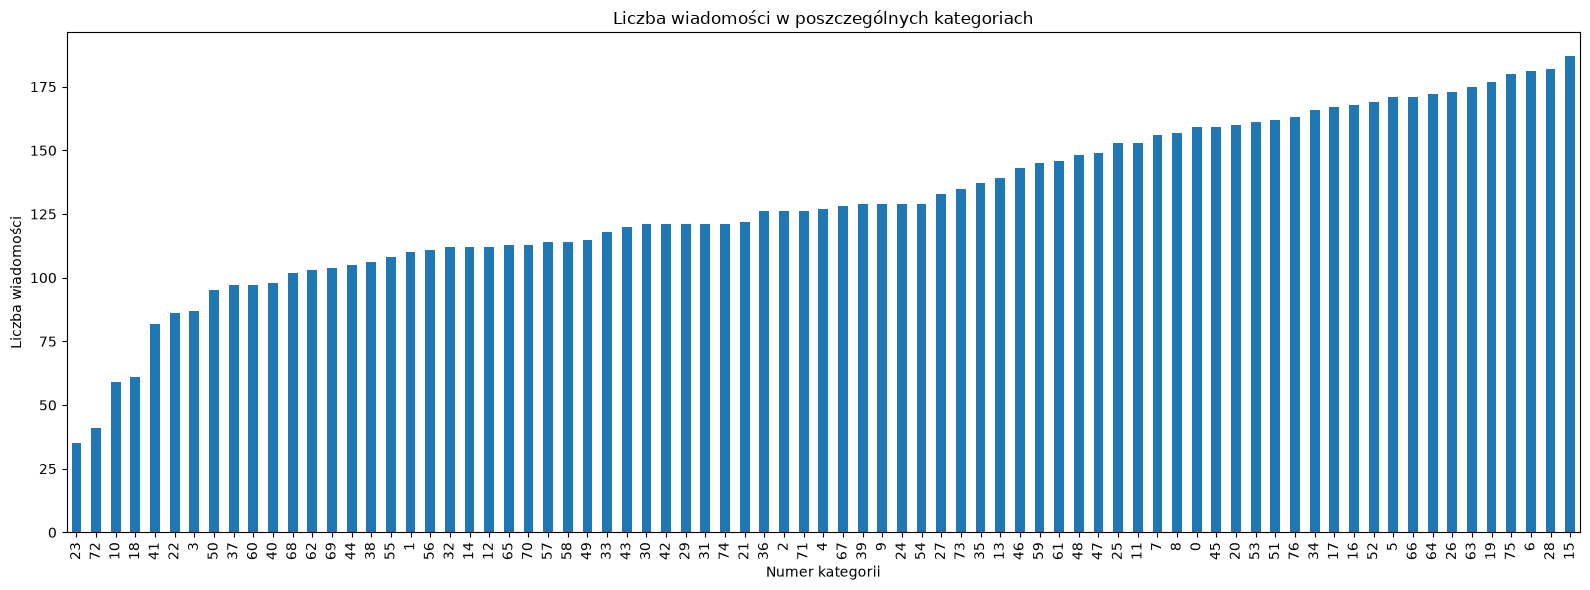

In [6]:
import matplotlib.pyplot as plt

category_counts.sort_values().plot(
    kind="bar",
    figsize=(16, 6)
)

plt.title("Liczba wiadomości w poszczególnych kategoriach")
plt.xlabel("Numer kategorii")
plt.ylabel("Liczba wiadomości")
plt.tight_layout()
plt.show()

Krok 6. Sprawdzenie brakujących danych i duplikatów

In [7]:
print("Brakujące wartości:")
print(train_df.isnull().sum())

print("\nDuplikaty:")
print(train_df.duplicated().sum())

print("\nDuplikaty wiadomości:")
print(train_df["text"].duplicated().sum())

Brakujące wartości:
text     0
label    0
dtype: int64

Duplikaty:
0

Duplikaty wiadomości:
0
Brakujące wartości:
text     0
label    0
dtype: int64

Duplikaty:
0

Duplikaty wiadomości:
0


Krok 7. Wyświetlenie przykładowych wiadomości

In [8]:
for category in train_df["label"].unique()[:5]:
    print(f"\nKategoria: {category}")

    examples = train_df[
        train_df["label"] == category
    ]["text"].head(3)

    for example in examples:
        print("-", example)


Kategoria: 11
- I am still waiting on my card?
- What can I do if my card still hasn't arrived after 2 weeks?
- I have been waiting over a week. Is the card still coming?

Kategoria: 13
- My card has been found. Is there any way for me to put it back into the app?
- I was able to find my card. How to I go about putting it into my app?
- how do I get my card to show in the app?

Kategoria: 32
- What is my money worth in other countries?
- Will my money be of equal value when I travel abroad?
- Do you know the rate of exchange?

Kategoria: 17
- Last Saturday, I was charged extra for the exchange rate on my payment. Is something wrong?
- Hi, I am disappointed to see such a bad exchange rate and hope you can assist me. Would you be able to confirm the official interbank exchange rate for me?
- I think the currency exchange that's been applied is wrong.

Kategoria: 34
- Why is there an extra fee on my statement?
- Why did they charge me an extra $1?
- Why is there a 1 euro fee on my statem